# Lab 3 – Testing honestly
*Session 4 · about 2 hours*

A single accuracy number hides a lot. Today we ask: **which** labels are confused, how **biologically** wrong are
the mistakes, and – most important – would the classifier work on a **new expedition**?

We use the best combination from Lab 2: CNN features + logistic regression.

In [1]:
# Run this cell first. On Google Colab it fetches the course; on your own computer it only loads the data.
import os, subprocess, sys
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("/content/fathomnetchallange").exists():
        if Path("/content/fathomnetchallange.zip").exists():      # zip from your tutor (drag it into Files)
            subprocess.run(["unzip", "-q", "/content/fathomnetchallange.zip", "-d", "/content"], check=True)
        else:
            subprocess.run(["git", "clone", "-q", "https://github.com/TorbenGl/fathomnetchallange",
                            "/content/fathomnetchallange"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "fathomnet"], check=True)
    os.chdir("/content/fathomnetchallange/course")
sys.path.insert(0, str(Path.cwd()))

from setup_env import setup
ROOT = setup()          # first time: downloads the crops (~15 min). setup(per_category=100) is a quick subset.

import warnings; warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from classifier_lab import data, features, models, evaluate
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

Dataset ready: /home/user/fathomnetchallange/fathomnet2025_compact  (23698 crop files; exact duplicate boxes are dropped when loading)


In [2]:
df = data.set_target(data.load_dataset(), "label")
X = features.cnn_embedding(df)
tax = data.load_taxonomy()
y = df["y"].to_numpy()

def fit_predict(how, seed=0, clf_name="logistic_regression"):
    train, test = data.split(df, how, seed=seed)
    tr = df["annotation_id"].isin(train["annotation_id"]).to_numpy()
    clf = models.make(clf_name).fit(X[tr], y[tr])
    return tr, clf.predict(X[~tr]), clf

tr, pred, clf = fit_predict("random")
truth = y[~tr]
print(evaluate.scores(truth, pred))

{'accuracy': 0.6372549019607843, 'balanced_accuracy': 0.6373264473073732, 'macro_f1': 0.6364837151688674}


## 1. Three scores
* **accuracy** – fraction of test crops labelled correctly.
* **balanced accuracy** – the accuracy of each label separately (its *recall*), then averaged: every label counts equally.
* **macro-F1** – like balanced accuracy, but also punishes labels that are *predicted too often* (low *precision*).

With ~300 crops per label all three are similar here. They differ a lot when some labels are rare – for example in a
real survey, where 90 % of the animals may be one species.

> ### ✍️ Q1
> A survey video contains 900 brittle stars and 100 sea pens. A classifier that always answers 'brittle star' has what accuracy? What balanced accuracy? Which number would you report, and why?

*Your answer:*

## 2. Which labels are easy, which are hard?

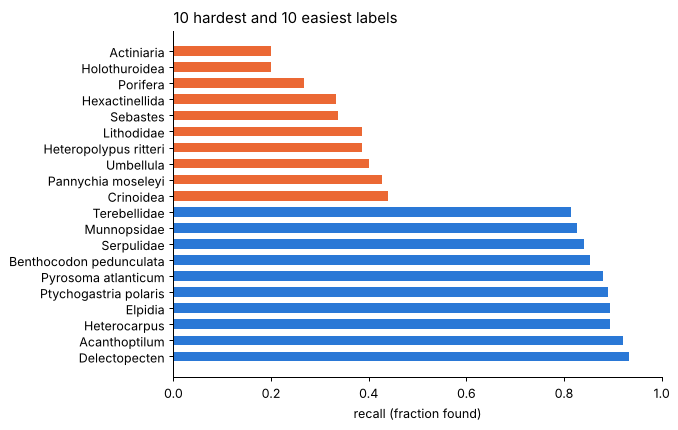

In [3]:
pl = evaluate.per_label(truth, pred)
fig, ax = plt.subplots(figsize=(7, 5))
show = pd.concat([pl.head(10), pl.tail(10)])
ax.barh(show.index, show["recall"], color=[evaluate.ORANGE] * 10 + [evaluate.BLUE] * 10, height=.6)
ax.set_xlim(0, 1); ax.set_xlabel("recall (fraction found)"); ax.set_title("10 hardest and 10 easiest labels", loc="left")
ax.invert_yaxis();

In [4]:
pl.join(tax[["label_rank", "phylum"]]).groupby("label_rank")["recall"].agg(["mean", "size"]).sort_values("mean")

,mean,size
label_rank,,
phylum,0.266667,1
class,0.435556,6
subfamily,0.506667,1
order,0.557778,6
subphylum,0.600000,1
infraorder,0.600000,1
gigaclass,0.626667,1
family,0.639257,8
species,0.674244,33


> ### ✍️ Q2
> Are species-level labels easier or harder than labels at higher ranks (family, order, class)? Explain with biology: what does a crop labelled with a *class* name look like compared with one labelled with a *species* name?

*Your answer:*

## 3. The confusion matrix
Rows = true label, columns = predicted label. The diagonal holds the correct answers; everything else is a mistake.
With 79 labels the matrix is big, so we first look at it **by phylum** (we translate both truth and prediction to
their phylum), then at the labels of one phylum.

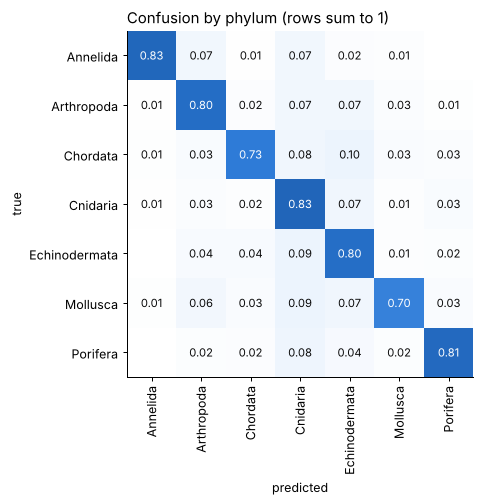

In [5]:
to_phylum = tax["phylum"].to_dict()
fig, ax = plt.subplots(figsize=(6, 5))
evaluate.plot_confusion([to_phylum[t] for t in truth], [to_phylum[p] for p in pred], ax=ax)
ax.set_title("Confusion by phylum (rows sum to 1)", loc="left");

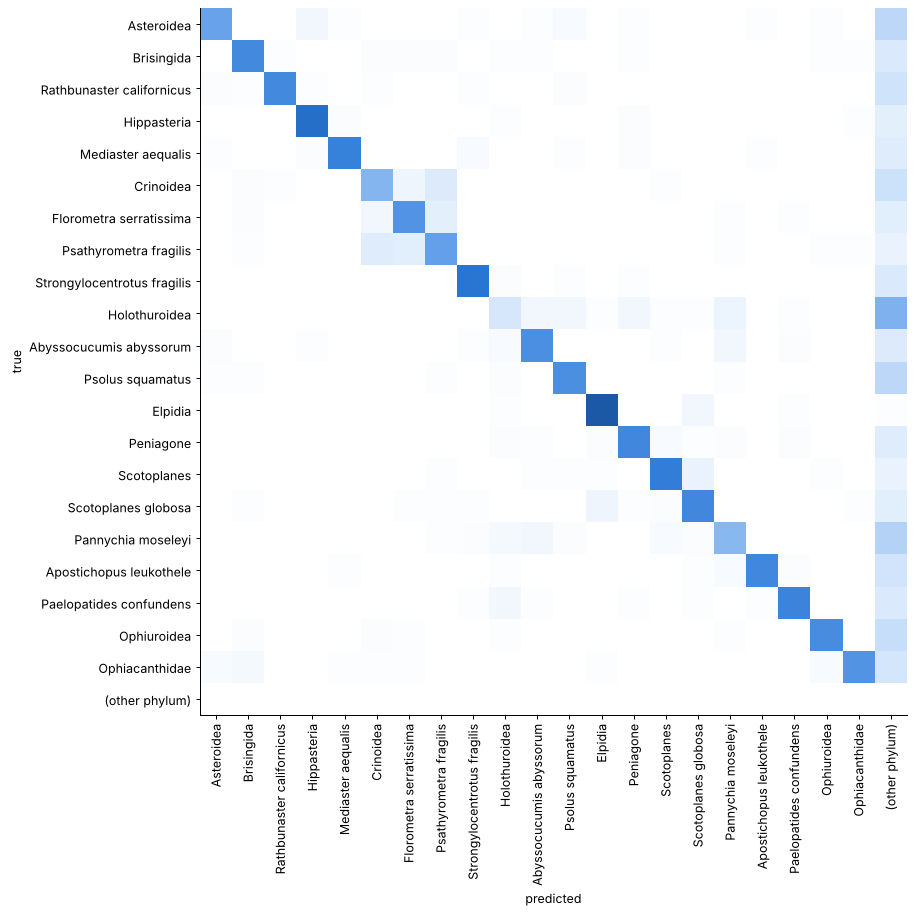

In [6]:
PHYLUM = "Echinodermata"          # <- try Cnidaria, Porifera, Arthropoda, Chordata ...
labs = [l for l in tax.sort_values(["class", "order", "family", "genus", "label_rank"]).index if to_phylum[l] == PHYLUM]
m = np.isin(truth, labs)
pred_m = [p if p in labs else "(other phylum)" for p in pred[m]]
evaluate.plot_confusion(truth[m], pred_m, labels=labs + ["(other phylum)"], annotate=False);

> ### ✍️ Q3
> Find the biggest off-diagonal cell in the matrix for your phylum. Which two labels are confused? Show crops of both (Lab 0, `data.show_examples`). Would a human expert confuse them too?

*Your answer:*

## 4. How *biologically* wrong are the mistakes?
For every mistake we ask: up to which rank do the true and the predicted label still agree?
Confusing two *Sebastes* species agrees up to the genus (a near miss). Confusing a sea star with a sea anemone
agrees only in the kingdom Animalia (a far miss). This is the idea behind the FathomNet 2025 score.

,accuracy if we only ask for this rank
phylum,80.0%
class,75.9%
order,73.0%
family,70.0%
genus,69.0%
species,67.4%


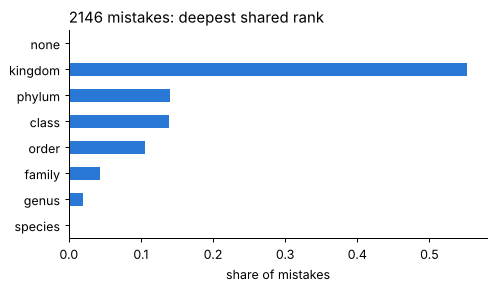

In [7]:
rep = evaluate.taxonomic_report(truth, pred, tax)
display(rep["accuracy_at_rank"].to_frame("accuracy if we only ask for this rank").style.format("{:.1%}"))
sev = rep["mistakes_agree_up_to"]
ax = (sev / sev.sum()).plot.barh(color=evaluate.BLUE, figsize=(6, 3))
ax.set_xlabel("share of mistakes"); ax.set_title(f"{rep['n_mistakes']} mistakes: deepest shared rank", loc="left");

> ### ✍️ Q4
> Are most mistakes near misses (same genus/family) or far misses (different phylum)? For a biodiversity survey, which kind of mistake is worse, and why?

*Your answer:*

## 5. The big one: random split vs. new dives
So far crops were assigned to train and test **at random**. But frames of the same dive – often of the same
individual animal – end up on both sides. That is like an exam that reuses the practice questions.

Now we split three ways:
* `random` – crop by crop,
* `image` – all crops of one video frame stay together,
* `dive` – all crops of one dive stay together: **the classifier is tested on expeditions it has never seen**.

In [8]:
rows = []
for how in ["random", "image", "dive"]:
    for seed in [0, 1, 2]:
        tr_, pred_, _ = fit_predict(how, seed)
        ov = data.overlap_report(df[tr_], df[~tr_])
        rows.append({"split": how, "seed": seed, **evaluate.scores(y[~tr_], pred_),
                     "test crops from a dive seen in training": ov["share_dive_with_train"] / ov["test_crops"]})
splits = pd.DataFrame(rows)
summary = splits.groupby("split", sort=False)[["accuracy", "macro_f1", "test crops from a dive seen in training"]].mean()
summary.style.format("{:.1%}")

,accuracy,macro_f1,test crops from a dive seen in training
split,,,
random,63.5%,63.3%,97.0%
image,57.5%,57.3%,91.3%
dive,49.6%,47.4%,0.0%


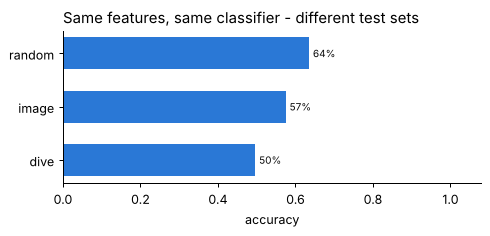

In [9]:
ax = evaluate.plot_comparison(summary.reset_index().rename(columns={"split": "name"}), "accuracy",
                              title="Same features, same classifier - different test sets")

> ### ✍️ Q5
> How large is the drop from `random` to `dive`? Explain *why* it happens, using what you saw in Lab 0 (§5). Which number would you put in a paper or a survey report – and why?

*Your answer:*

> ### ✍️ Q6
> The prize-winning FathomNet models scored ~98 % on crops they had trained on, ~63–66 % on new images and ~57–61 % on images from new dives. Compare with your numbers. What does this tell you about how far '99 % accuracy' claims in the news can be trusted?

*Your answer:*

## 6. Look at the mistakes
Confident and wrong is the most dangerous combination for a survey. Below: test crops from the **dive** split that
were labelled wrongly with high confidence.

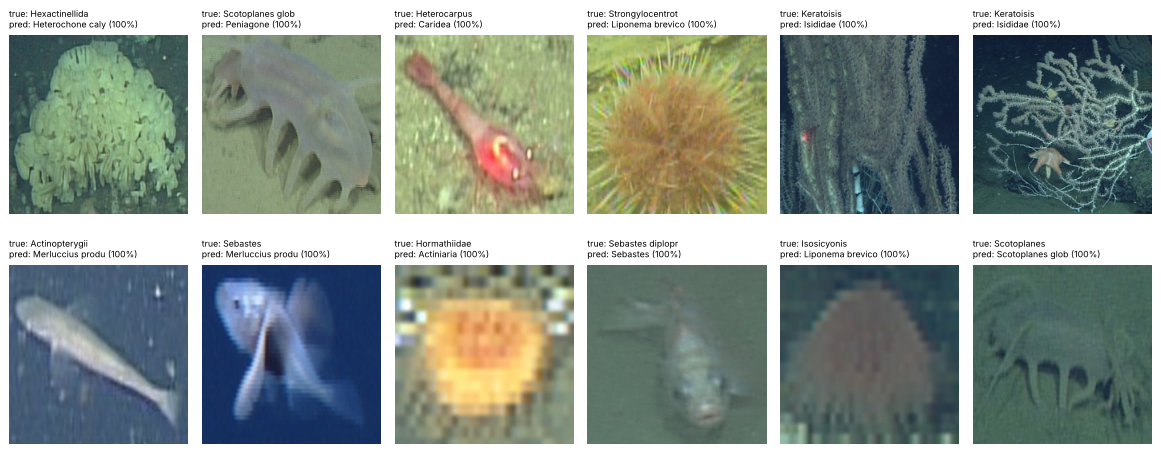

In [10]:
tr_d, pred_d, clf_d = fit_predict("dive", 0)
proba = clf_d.predict_proba(X[~tr_d]).max(axis=1)
wrong = df[~tr_d].assign(pred=pred_d, conf=proba)
wrong = wrong[wrong["y"] != wrong["pred"]].sort_values("conf", ascending=False).head(12)
fig, axes = plt.subplots(2, 6, figsize=(13, 5.5))
for ax, (_, r) in zip(axes.ravel(), wrong.iterrows()):
    ax.imshow(Image.open(r["path"])); ax.axis("off")
    ax.set_title(f"true: {r['y'][:16]}\npred: {r['pred'][:16]} ({r['conf']:.0%})", fontsize=7, loc="left")
fig.tight_layout()

> ### ✍️ Q7
> Pick three of these mistakes. For each: is it a mistake of the classifier, a hard/blurry crop, or might the expert label itself be questionable?

*Your answer:*

**Hand-in for Lab 3:** the phylum confusion matrix, the split comparison chart, and half a page answering:
*Which mistakes does the classifier make, how biologically severe are they, and how well would it do on a new expedition?*